# 10. 머신러닝 모델 템플릿

**AICE Associate 학습 10단계**

시험의 **AI 모델링 영역(50점)** 중 머신러닝 문항(10~12번)은 다음 흐름을 그대로 따릅니다.

```
데이터 준비(X, y 분리) → train_test_split → 스케일링 → 모델 생성 → fit → predict → 평가 → (튜닝, 변수중요도)
```

이 노트북은 **처음부터 끝까지 복사해서 쓸 수 있는 템플릿**입니다. 분류(Titanic 생존 예측)와 회귀(청구 금액 예측)를 모두 다룹니다.

### scikit-learn 모델 공통 사용법 (이것만 기억!)
```python
model = 모델클래스(하이퍼파라미터=값, random_state=시드)   # 1. 생성
model.fit(X_train, y_train)                                  # 2. 학습
y_pred = model.predict(X_valid)                              # 3. 예측
score = 평가함수(y_valid, y_pred)                            # 4. 평가 (정답, 예측 순서)
```

In [1]:
import platform
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib.font_manager as fm
import warnings
warnings.filterwarnings('ignore')

# OS에 따라서 한글 폰트 로드
os_name = platform.system()

if os_name == 'Linux':
    font_names = [f.name for f in fm.fontManager.ttflist]
    for cand in ['NanumGothicCoding', 'NanumGothic', 'Noto Sans CJK KR', 'Noto Sans CJK JP']:
        if cand in font_names:
            plt.rc('font', family=cand)
            break
    print("(리눅스) 한글폰트 로드 완료")
elif os_name == 'Windows':
    font_path = 'C:\\Windows\\Fonts\\malgun.ttf'
    font = fm.FontProperties(fname=font_path).get_name()
    mpl.rc('font', family=font)
    print("(윈도우) 한글폰트 로드 완료")
elif os_name == 'Darwin':
    plt.rc('font', family='AppleGothic')
    print("(맥) 한글폰트 로드 완료")
else:
    print(f"알 수 없는 OS입니다: {os_name}")

# 마이너스 기호 깨짐 방지
mpl.rcParams['axes.unicode_minus'] = False

(리눅스) 한글폰트 로드 완료


---
# Part 1. 분류(Classification) 템플릿 — Titanic 생존 예측

## 1. 데이터 준비

In [2]:
df = pd.read_csv('titanic.csv')
print(df.shape)
df.head()

(891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
df.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [4]:
# 1) 불필요한 컬럼 삭제 (식별자, 자유 텍스트, 결측이 너무 많은 컬럼)
data = df.drop(['PassengerId', 'Name', 'Ticket', 'Cabin'], axis=1)

# 2) 결측치 처리
data['Age'] = data['Age'].fillna(data['Age'].median())
data['Embarked'] = data['Embarked'].fillna(data['Embarked'].mode()[0])

# 3) 원-핫 인코딩
data = pd.get_dummies(data=data, columns=['Sex', 'Embarked'], drop_first=True)
data.head()

,Survived,Pclass,Age,SibSp,Parch,Fare,Sex_male,Embarked_Q,Embarked_S
0,0,3,22.0,1,0,7.2500,True,False,True
1,1,1,38.0,1,0,71.2833,False,False,False
2,1,3,26.0,0,0,7.9250,False,False,True
3,1,1,35.0,1,0,53.1000,False,False,True
4,0,3,35.0,0,0,8.0500,True,False,True


In [5]:
# 4) X, y 분리
X = data.drop('Survived', axis=1)
y = data['Survived']

# 5) 학습/검증 분리 (분류는 stratify=y 권장)
from sklearn.model_selection import train_test_split
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print(X_train.shape, X_valid.shape)

(712, 8) (179, 8)


In [6]:
# 6) 스케일링 (fit은 학습 데이터에만!)
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_valid_s = scaler.transform(X_valid)

---
## 2. 주요 분류 모델

| 모델 | 클래스 | 주요 하이퍼파라미터 |
|---|---|---|
| 로지스틱 회귀 | `LogisticRegression` | `C`, `max_iter` |
| K-최근접 이웃 | `KNeighborsClassifier` | `n_neighbors` |
| 의사결정나무 | `DecisionTreeClassifier` | `max_depth`, `min_samples_split`, `min_samples_leaf`, `random_state` |
| 랜덤포레스트 | `RandomForestClassifier` | `n_estimators`, `max_depth`, `min_samples_split`, `random_state` |
| XGBoost | `XGBClassifier` | `n_estimators`, `max_depth`, `learning_rate` |
| LightGBM | `LGBMClassifier` | `n_estimators`, `max_depth`, `learning_rate` |

In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

In [8]:
# 로지스틱 회귀
lg = LogisticRegression(max_iter=1000)
lg.fit(X_train_s, y_train)
lg_pred = lg.predict(X_valid_s)
print("LogisticRegression acc:", accuracy_score(y_valid, lg_pred))

LogisticRegression acc: 0.8044692737430168


In [9]:
# KNN (거리 기반 → 스케일링 필수)
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_s, y_train)
print("KNN acc:", accuracy_score(y_valid, knn.predict(X_valid_s)))

KNN acc: 0.8156424581005587


In [10]:
# 의사결정나무 (트리 계열은 스케일링 영향이 거의 없음)
dt = DecisionTreeClassifier(max_depth=5, min_samples_split=3, random_state=42)
dt.fit(X_train_s, y_train)
dt_pred = dt.predict(X_valid_s)
print("DecisionTree acc:", accuracy_score(y_valid, dt_pred))

DecisionTree acc: 0.7653631284916201


In [11]:
# 랜덤포레스트
rf = RandomForestClassifier(n_estimators=200, max_depth=7, random_state=42)
rf.fit(X_train_s, y_train)
rf_pred = rf.predict(X_valid_s)
print("RandomForest acc:", accuracy_score(y_valid, rf_pred))

RandomForest acc: 0.7988826815642458


In [12]:
# XGBoost / LightGBM (설치되어 있을 때만 실행)
try:
    from xgboost import XGBClassifier
    xgb = XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.05, random_state=42)
    xgb.fit(X_train_s, y_train)
    print("XGBoost acc:", accuracy_score(y_valid, xgb.predict(X_valid_s)))
except ImportError:
    print("xgboost 미설치 (pip install xgboost)")

try:
    from lightgbm import LGBMClassifier
    lgbm = LGBMClassifier(n_estimators=200, max_depth=4, learning_rate=0.05, random_state=42, verbose=-1)
    lgbm.fit(X_train_s, y_train)
    print("LightGBM acc:", accuracy_score(y_valid, lgbm.predict(X_valid_s)))
except ImportError:
    print("lightgbm 미설치 (pip install lightgbm)")

XGBoost acc: 0.7988826815642458
LightGBM acc: 0.7932960893854749


---
## 3. 분류 평가지표

| 지표 | 의미 | 함수 |
|---|---|---|
| Accuracy | 전체 중 맞춘 비율 | `accuracy_score` |
| Precision (정밀도) | 1로 예측한 것 중 실제 1 | `precision_score` |
| Recall (재현율) | 실제 1 중 1로 맞춘 비율 | `recall_score` |
| F1 | 정밀도와 재현율의 조화평균 | `f1_score` |
| ROC-AUC | 확률 기반 순위 성능 | `roc_auc_score(y, proba)` |

> 이탈 예측처럼 **1(이탈)이 적은 불균형 데이터**에서는 Accuracy보다 **Recall, F1**을 함께 봐야 합니다.

[[101   9]
 [ 27  42]]


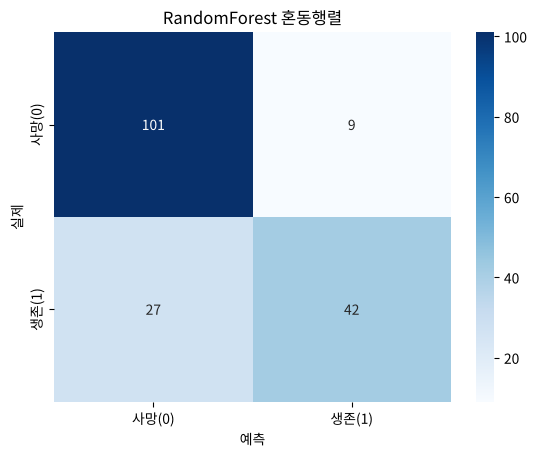

In [13]:
from sklearn.metrics import confusion_matrix, classification_report, precision_score, recall_score, f1_score, roc_auc_score

cm = confusion_matrix(y_valid, rf_pred)
print(cm)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['사망(0)', '생존(1)'], yticklabels=['사망(0)', '생존(1)'])
plt.xlabel('예측')
plt.ylabel('실제')
plt.title('RandomForest 혼동행렬')
plt.show()

In [14]:
print(classification_report(y_valid, rf_pred))

              precision    recall  f1-score   support

           0       0.79      0.92      0.85       110
           1       0.82      0.61      0.70        69

    accuracy                           0.80       179
   macro avg       0.81      0.76      0.77       179
weighted avg       0.80      0.80      0.79       179



In [15]:
print("precision:", precision_score(y_valid, rf_pred))
print("recall   :", recall_score(y_valid, rf_pred))
print("f1       :", f1_score(y_valid, rf_pred))

# predict_proba: 각 클래스의 확률 → [:, 1] 이 1일 확률
rf_proba = rf.predict_proba(X_valid_s)[:, 1]
print("roc_auc  :", roc_auc_score(y_valid, rf_proba))

precision: 0.8235294117647058
recall   : 0.6086956521739131
f1       : 0.7
roc_auc  : 0.8428194993412386


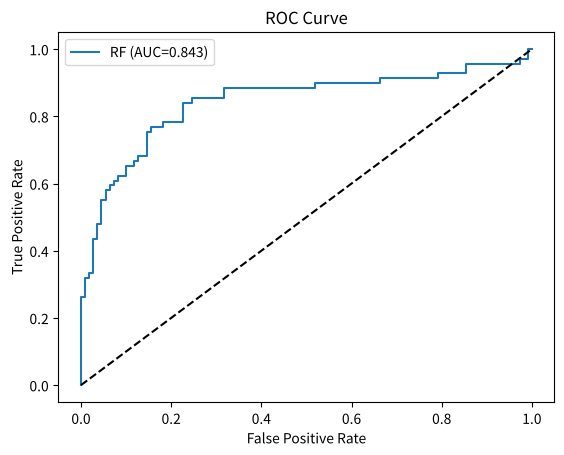

In [16]:
# ROC 곡선
from sklearn.metrics import roc_curve
fpr, tpr, _ = roc_curve(y_valid, rf_proba)
plt.plot(fpr, tpr, label=f'RF (AUC={roc_auc_score(y_valid, rf_proba):.3f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.title('ROC Curve')
plt.show()

---
## 4. 모델 성능 비교

In [17]:
models = {
    'LogisticRegression': lg,
    'KNN': knn,
    'DecisionTree': dt,
    'RandomForest': rf,
}
rows = []
for name, m in models.items():
    p = m.predict(X_valid_s)
    rows.append({'model': name, 'accuracy': accuracy_score(y_valid, p), 'recall': recall_score(y_valid, p), 'f1': f1_score(y_valid, p)})
result = pd.DataFrame(rows).sort_values('accuracy', ascending=False)
result

,model,accuracy,recall,f1
1,KNN,0.815642,0.695652,0.744186
0,LogisticRegression,0.804469,0.666667,0.724409
3,RandomForest,0.798883,0.608696,0.700000
2,DecisionTree,0.765363,0.579710,0.655738


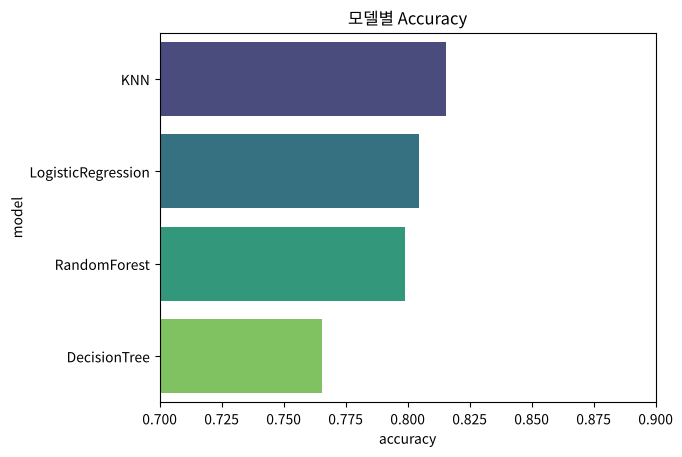

In [18]:
sns.barplot(data=result, x='accuracy', y='model', palette='viridis')
plt.xlim(0.7, 0.9)
plt.title('모델별 Accuracy')
plt.show()

---
## 5. 하이퍼파라미터 튜닝: `GridSearchCV` ★

후보값의 **모든 조합**을 교차검증(cv)으로 평가해 가장 좋은 조합을 찾습니다.

| 속성 | 의미 |
|---|---|
| `best_params_` | 최적 하이퍼파라미터 조합 (딕셔너리) |
| `best_score_` | 최적 조합의 교차검증 평균 점수 |
| `best_estimator_` | 최적 조합으로 **전체 학습데이터에 다시 학습된 모델** |

In [19]:
from sklearn.model_selection import GridSearchCV

param_grid_rf = {
    'n_estimators': [100, 200],
    'max_depth': [5, 7, 10],
    'min_samples_split': [2, 5]
}
gs_rf = GridSearchCV(estimator=RandomForestClassifier(random_state=42),
                     param_grid=param_grid_rf,
                     cv=3,
                     scoring='accuracy',
                     n_jobs=-1)
gs_rf.fit(X_train_s, y_train)

print("best_params_:", gs_rf.best_params_)
print("best_score_ :", round(gs_rf.best_score_, 4))
print(gs_rf.best_estimator_)

best_params_: {'max_depth': 10, 'min_samples_split': 5, 'n_estimators': 100}
best_score_ : 0.8301
RandomForestClassifier(max_depth=10, min_samples_split=5, random_state=42)


In [20]:
# 최적 모델로 검증 데이터 평가
best_rf = gs_rf.best_estimator_
print("검증 accuracy:", accuracy_score(y_valid, best_rf.predict(X_valid_s)))
# GridSearchCV 객체로 바로 predict 해도 best_estimator_가 사용됩니다
print("검증 accuracy:", accuracy_score(y_valid, gs_rf.predict(X_valid_s)))

검증 accuracy: 0.7988826815642458
검증 accuracy: 0.7988826815642458


In [21]:
# 전체 탐색 결과 보기
pd.DataFrame(gs_rf.cv_results_)[['params', 'mean_test_score', 'rank_test_score']].sort_values('rank_test_score').head()

,params,mean_test_score,rank_test_score
10,"{'max_depth': 10, 'min_samples_split': 5, 'n_e...",0.830083,1
11,"{'max_depth': 10, 'min_samples_split': 5, 'n_e...",0.830077,2
8,"{'max_depth': 10, 'min_samples_split': 2, 'n_e...",0.824451,3
0,"{'max_depth': 5, 'min_samples_split': 2, 'n_es...",0.821644,4
9,"{'max_depth': 10, 'min_samples_split': 2, 'n_e...",0.821644,4


In [22]:
# 참고: RandomizedSearchCV (조합이 많을 때 n_iter개만 무작위 탐색), cross_val_score
from sklearn.model_selection import RandomizedSearchCV, cross_val_score
rs_dt = RandomizedSearchCV(DecisionTreeClassifier(random_state=42),
                           {'max_depth': range(2, 15), 'min_samples_leaf': range(1, 20)},
                           n_iter=20, cv=3, random_state=42, n_jobs=-1)
rs_dt.fit(X_train_s, y_train)
print(rs_dt.best_params_)

scores = cross_val_score(DecisionTreeClassifier(max_depth=4, random_state=42), X_train_s, y_train, cv=5, scoring='accuracy')
print("5-fold accuracy:", scores.round(3), "평균:", scores.mean().round(3))

{'min_samples_leaf': 5, 'max_depth': 13}
5-fold accuracy: [0.825 0.755 0.852 0.831 0.817] 평균: 0.816


---
## 6. 변수 중요도: `feature_importances_` ★

트리 계열 모델(DecisionTree, RandomForest, XGBoost, LightGBM)은 학습 후 `feature_importances_` 속성을 가집니다.
(샘플 문항 11번: `rf.importances` → `rf.feature_importances_`, `sort_index` → `sort_values` 오류 정정)

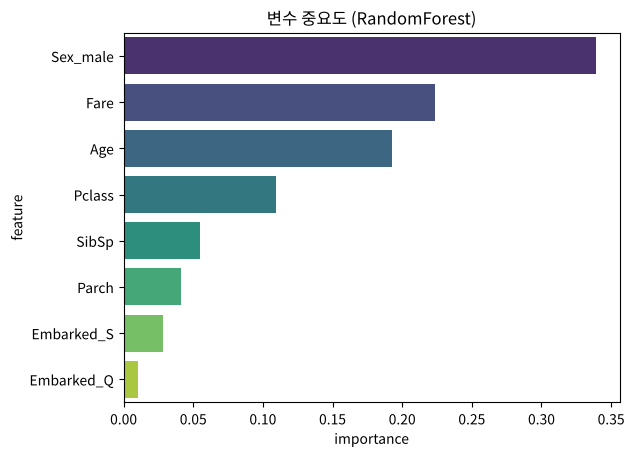

가장 중요한 변수: Sex_male


In [23]:
fi = pd.DataFrame({'feature': X.columns, 'importance': best_rf.feature_importances_})
fi = fi.sort_values('importance', ascending=False)[:10]
sns.barplot(x='importance', y='feature', data=fi, palette='viridis')
plt.title('변수 중요도 (RandomForest)')
plt.show()
print("가장 중요한 변수:", fi.iloc[0]['feature'])

In [24]:
# 로지스틱 회귀는 coef_ (계수) 로 영향 방향과 크기를 봅니다
pd.Series(lg.coef_[0], index=X.columns).sort_values()

Sex_male     -1.269598
Pclass       -0.928698
Age          -0.502878
SibSp        -0.262672
Embarked_S   -0.171784
Parch        -0.067158
Embarked_Q    0.080683
Fare          0.099599
dtype: float64

---
## 7. 새로운 데이터 예측

In [25]:
new = pd.DataFrame([{'Pclass': 1, 'Age': 30, 'SibSp': 0, 'Parch': 0, 'Fare': 80,
                     'Sex_male': False, 'Embarked_Q': False, 'Embarked_S': True}])[X.columns]
new_s = scaler.transform(new)        # 학습 때와 같은 스케일러!
print("예측:", best_rf.predict(new_s), "생존확률:", best_rf.predict_proba(new_s)[:, 1].round(3))

예측: [1] 생존확률: [0.996]


---
# Part 2. 회귀(Regression) 템플릿 — 평균 청구 금액 예측

타깃이 **연속된 숫자**이면 회귀 문제입니다. 모델 이름 끝이 `Classifier` → `Regressor`로 바뀌고, 평가지표가 달라집니다.

| 지표 | 의미 | 함수 | 좋은 방향 |
|---|---|---|---|
| MAE | 평균 절대 오차 | `mean_absolute_error` | 낮을수록 |
| MSE | 평균 제곱 오차 | `mean_squared_error` | 낮을수록 |
| RMSE | MSE의 제곱근 | `np.sqrt(mean_squared_error(...))` | 낮을수록 |
| R² | 결정계수 (설명력) | `r2_score` | 1에 가까울수록 |

In [26]:
cust = pd.read_csv('cust_data.csv')
reg = cust.drop(['A_bill', 'B_bill'], axis=1)              # 타깃과 직접 연결된 컬럼 제외
reg = pd.get_dummies(reg, columns=['class', 'sex', 'stop', 'npay', 'termination'], drop_first=True)
X_r = reg.drop('avg_bill', axis=1)
y_r = reg['avg_bill']
Xr_train, Xr_valid, yr_train, yr_valid = train_test_split(X_r, y_r, test_size=0.2, random_state=42)   # 회귀는 stratify 없음

from sklearn.preprocessing import MinMaxScaler
mm = MinMaxScaler()
Xr_train = mm.fit_transform(Xr_train)
Xr_valid = mm.transform(Xr_valid)
print(Xr_train.shape, Xr_valid.shape)

(7944, 13) (1986, 13)


In [27]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

reg_models = {
    'LinearRegression': LinearRegression(),
    'DecisionTree': DecisionTreeRegressor(max_depth=5, min_samples_split=3, random_state=120),
    'RandomForest': RandomForestRegressor(max_depth=5, min_samples_split=3, random_state=120),
}
rows = []
for name, m in reg_models.items():
    m.fit(Xr_train, yr_train)
    p = m.predict(Xr_valid)
    rows.append({'model': name,
                 'MAE': mean_absolute_error(yr_valid, p),
                 'MSE': mean_squared_error(yr_valid, p),
                 'RMSE': np.sqrt(mean_squared_error(yr_valid, p)),
                 'R2': r2_score(yr_valid, p)})
pd.DataFrame(rows).round(3)

,model,MAE,MSE,RMSE,R2
0,LinearRegression,6900.225,8.000296e+07,8944.437,0.143
1,DecisionTree,7097.591,8.378277e+07,9153.293,0.103
2,RandomForest,7000.490,8.186597e+07,9047.982,0.123


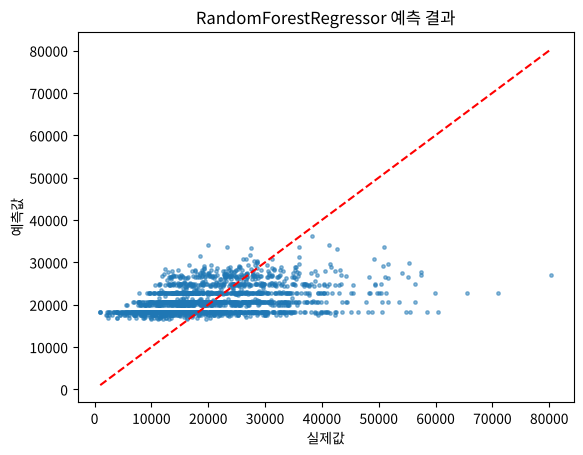

In [28]:
# 실제값 vs 예측값 산점도
p = reg_models['RandomForest'].predict(Xr_valid)
plt.scatter(yr_valid, p, s=6, alpha=0.5)
lim = [yr_valid.min(), yr_valid.max()]
plt.plot(lim, lim, 'r--')
plt.xlabel('실제값')
plt.ylabel('예측값')
plt.title('RandomForestRegressor 예측 결과')
plt.show()

---
## 8. 모델 저장/불러오기 (참고)

In [29]:
import joblib
joblib.dump(best_rf, 'titanic_rf.pkl')
loaded = joblib.load('titanic_rf.pkl')
print(accuracy_score(y_valid, loaded.predict(X_valid_s)))

0.7988826815642458


---
## 📋 머신러닝 문항 체크리스트

- [ ] 분류인가 회귀인가? → `Classifier` / `Regressor`
- [ ] 문항에 지정된 **변수명**(`dt`, `rf`, `gs_dt`, `y_pred_dt` ...) 그대로 사용했는가?
- [ ] `random_state`, `max_depth`, `min_samples_split`, `n_estimators`, `cv`, `scoring`, `n_jobs` 값이 문항과 같은가?
- [ ] `fit(X_train, y_train)` 으로 학습했는가?
- [ ] 예측은 `predict(X_valid)` (검증 데이터!) 로 했는가?
- [ ] 평가 함수 인자 순서: `(y_valid, y_pred)`
- [ ] GridSearchCV를 썼다면 평가와 변수중요도에 `gs.best_estimator_` 를 사용했는가?
- [ ] 성능 비교: Accuracy·R²는 **클수록**, MAE·MSE·RMSE는 **작을수록** 좋음